In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error, r2_score

url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/auto-mpg.data'
column_names = ['mpg', 'cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model_year', 'origin', 'car_name']
raw_dataset = pd.read_csv(url, names=column_names, na_values='?', comment='\t', sep=' ', skipinitialspace=True)

df = raw_dataset.copy()

df = df.dropna(subset=['horsepower'])

df['horsepower'] = pd.to_numeric(df['horsepower'])

X = df[['displacement']]
y = df['mpg']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Dataset loaded and preprocessed successfully.")
print(f"Training data shape: X_train={X_train.shape}, y_train={y_train.shape}")
print(f"Testing data shape: X_test={X_test.shape}, y_test={y_test.shape}")

Dataset loaded and preprocessed successfully.
Training data shape: X_train=(313, 1), y_train=(313,)
Testing data shape: X_test=(79, 1), y_test=(79,)


In [13]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
y_pred_linear = linear_model.predict(X_test)

mse_linear = mean_squared_error(y_test, y_pred_linear)
r2_linear = r2_score(y_test, y_pred_linear)

print(f"\nLinear Regression:")
print(f"  Mean Squared Error (MSE): {mse_linear:.2f}")
print(f"  R-squared (R2): {r2_linear:.2f}")

polynomial_models = {}
polynomial_predictions = {}
polynomial_metrics = {}

degrees = [2, 3, 4]

for degree in degrees:
    poly_features = PolynomialFeatures(degree=degree)
    X_train_poly = poly_features.fit_transform(X_train)
    X_test_poly = poly_features.transform(X_test)

    model = LinearRegression()
    model.fit(X_train_poly, y_train)
    y_pred_poly = model.predict(X_test_poly)

    mse_poly = mean_squared_error(y_test, y_pred_poly)
    r2_poly = r2_score(y_test, y_pred_poly)

    polynomial_models[degree] = model
    polynomial_predictions[degree] = y_pred_poly
    polynomial_metrics[degree] = {'mse': mse_poly, 'r2': r2_poly}

    print(f"\nPolynomial Regression (Degree {degree}):")
    print(f"  Mean Squared Error (MSE): {mse_poly:.2f}")
    print(f"  R-squared (R2): {r2_poly:.2f}")


Linear Regression:
  Mean Squared Error (MSE): 21.23
  R-squared (R2): 0.58

Polynomial Regression (Degree 2):
  Mean Squared Error (MSE): 20.65
  R-squared (R2): 0.60

Polynomial Regression (Degree 3):
  Mean Squared Error (MSE): 20.82
  R-squared (R2): 0.59

Polynomial Regression (Degree 4):
  Mean Squared Error (MSE): 20.89
  R-squared (R2): 0.59


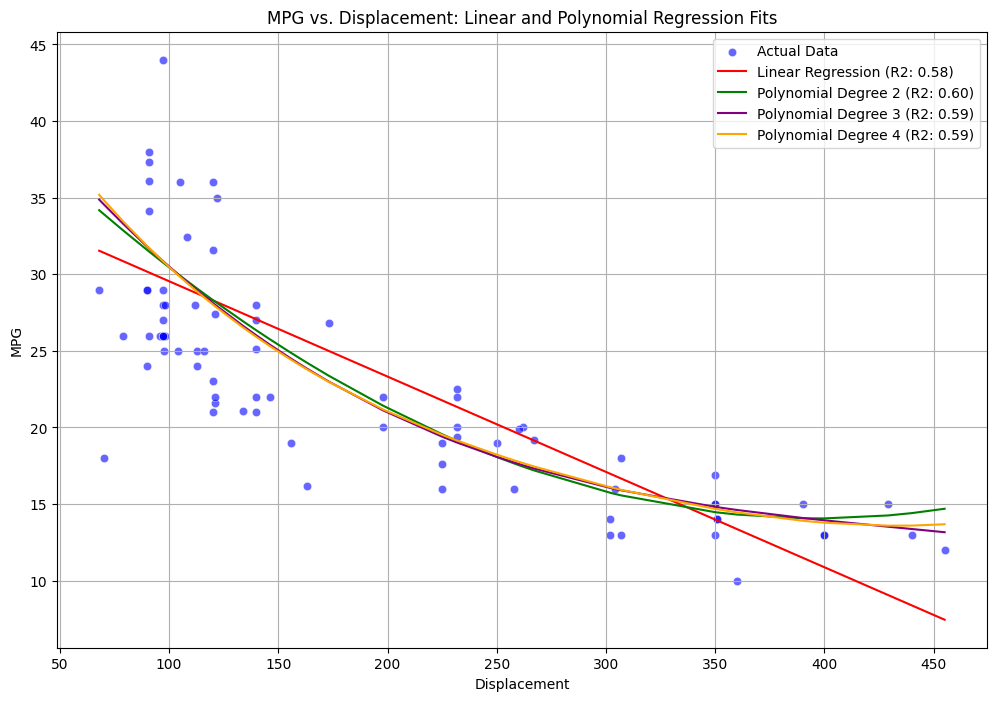

In [11]:
results = {
    'linear': {
        'model': linear_model,
        'predictions': y_pred_linear,
        'mse': mse_linear,
        'r2': r2_linear
    },
    'polynomial': {
        'models': polynomial_models,
        'predictions': polynomial_predictions,
        'metrics': polynomial_metrics
    }
}

plt.figure(figsize=(12, 8))
sns.scatterplot(x=X_test['displacement'], y=y_test, label='Actual Data', color='blue', alpha=0.6)

X_test_sorted = X_test.sort_values(by='displacement')

plt.plot(X_test_sorted['displacement'], linear_model.predict(X_test_sorted), color='red', label=f'Linear Regression (R2: {results["linear"]["r2"]:.2f})')

colors = ['green', 'purple', 'orange']
degree_idx = 0
for degree in degrees:
    poly_features = PolynomialFeatures(degree=degree)
    poly_features.fit(X_train)
    X_test_poly_sorted = poly_features.transform(X_test_sorted)
    y_pred_poly_sorted = polynomial_models[degree].predict(X_test_poly_sorted)
    plt.plot(X_test_sorted['displacement'], y_pred_poly_sorted, color=colors[degree_idx], label=f'Polynomial Degree {degree} (R2: {results["polynomial"]["metrics"][degree]["r2"]:.2f})')
    degree_idx += 1

plt.title('MPG vs. Displacement: Linear and Polynomial Regression Fits')
plt.xlabel('Displacement')
plt.ylabel('MPG')
plt.legend()
plt.grid(True)
plt.show()